In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/notebooks/shazahanybakr/dataset/__notebook__.ipynb
/kaggle/input/notebooks/shazahanybakr/dataset/__output__.json
/kaggle/input/notebooks/shazahanybakr/dataset/__results__.html
/kaggle/input/notebooks/shazahanybakr/dataset/custom.css
/kaggle/input/notebooks/shazahanybakr/dataset/dataset.py
/kaggle/input/notebooks/shazahanybakr/dataset/eda_summary.png
/kaggle/input/notebooks/shazahanybakr/dataset/__results___files/__results___5_2.png
/kaggle/input/notebooks/shazahanybakr/dataset/processed_data/test/images/M-33-20-D-c-4-2_105.jpg
/kaggle/input/notebooks/shazahanybakr/dataset/processed_data/test/images/M-33-20-D-c-4-2_110.jpg
/kaggle/input/notebooks/shazahanybakr/dataset/processed_data/test/images/M-33-20-D-c-4-2_117.jpg
/kaggle/input/notebooks/shazahanybakr/dataset/processed_data/test/images/M-33-20-D-c-4-2_120.jpg
/kaggle/input/notebooks/shazahanybakr/dataset/processed_data/test/images/M-33-20-D-c-4-2_124.jpg
/kaggle/input/notebooks/shazahanybakr/dataset/processed_data/test

In [2]:

import torch
import os

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("Please enable GPU from Notebook Settings.")

DATA_ROOT = "/kaggle/input/notebooks/shazahanybakr/dataset/processed_data"

print("Dataset exists:", os.path.exists(DATA_ROOT))

if os.path.exists(DATA_ROOT):
    print("Dataset files:", os.listdir(DATA_ROOT)[:10])


PyTorch version: 2.11.0+cu130
GPU available: True
GPU name: Tesla T4
Dataset exists: True
Dataset files: ['test', 'train', 'val']


In [3]:

import os
from collections import Counter

DATA_ROOT = "/kaggle/input/notebooks/shazahanybakr/dataset/processed_data"

for split in ["train", "val", "test"]:
    split_path = os.path.join(DATA_ROOT, split)

    print(f"\n{'='*40}")
    print(f"{split.upper()}")

    if not os.path.exists(split_path):
        print("Folder not found!")
        continue

    file_counts = Counter()
    samples = []

    for root, dirs, files in os.walk(split_path):
        for file in files:
            ext = os.path.splitext(file)[1].lower()
            file_counts[ext] += 1

            if len(samples) < 10:
                samples.append(os.path.join(root, file))

    print("File counts:", dict(file_counts))
    print("\nSample paths:")
    for path in samples:
        print(path)



TRAIN
File counts: {'.jpg': 7470, '.png': 7470}

Sample paths:
/kaggle/input/notebooks/shazahanybakr/dataset/processed_data/train/images/M-33-20-D-c-4-2_0.jpg
/kaggle/input/notebooks/shazahanybakr/dataset/processed_data/train/images/M-33-20-D-c-4-2_1.jpg
/kaggle/input/notebooks/shazahanybakr/dataset/processed_data/train/images/M-33-20-D-c-4-2_10.jpg
/kaggle/input/notebooks/shazahanybakr/dataset/processed_data/train/images/M-33-20-D-c-4-2_100.jpg
/kaggle/input/notebooks/shazahanybakr/dataset/processed_data/train/images/M-33-20-D-c-4-2_102.jpg
/kaggle/input/notebooks/shazahanybakr/dataset/processed_data/train/images/M-33-20-D-c-4-2_104.jpg
/kaggle/input/notebooks/shazahanybakr/dataset/processed_data/train/images/M-33-20-D-c-4-2_106.jpg
/kaggle/input/notebooks/shazahanybakr/dataset/processed_data/train/images/M-33-20-D-c-4-2_108.jpg
/kaggle/input/notebooks/shazahanybakr/dataset/processed_data/train/images/M-33-20-D-c-4-2_109.jpg
/kaggle/input/notebooks/shazahanybakr/dataset/processed_dat

In [4]:

from pathlib import Path
from PIL import Image
import numpy as np
import random

DATA_ROOT = Path(
    "/kaggle/input/notebooks/shazahanybakr/dataset/processed_data"
)

random.seed(42)

for split in ["train", "val", "test"]:

    image_dir = DATA_ROOT / split / "images"
    mask_dir = DATA_ROOT / split / "masks"

    images = {p.stem: p for p in image_dir.glob("*.jpg")}
    masks = {p.stem: p for p in mask_dir.glob("*.png")}

    image_names = set(images.keys())
    mask_names = set(masks.keys())

    missing_masks = image_names - mask_names
    missing_images = mask_names - image_names

    print(f"\n{'='*45}")
    print("SPLIT:", split.upper())
    print("Images:", len(images))
    print("Masks:", len(masks))
    print("Images without masks:", len(missing_masks))
    print("Masks without images:", len(missing_images))

    if missing_masks or missing_images:
        print("WARNING: Filename mismatch!")
        print("Missing masks examples:", list(missing_masks)[:5])
        print("Missing images examples:", list(missing_images)[:5])
        continue

    # Inspect 5 matching samples
    sample_names = random.sample(list(image_names), min(5, len(image_names)))

    for name in sample_names:
        image = Image.open(images[name])
        mask = Image.open(masks[name])

        mask_array = np.array(mask)

        print(
            f"\n{name}: "
            f"Image size={image.size}, "
            f"Mask size={mask.size}, "
            f"Mask shape={mask_array.shape}, "
            f"Labels={np.unique(mask_array)}"
        )



SPLIT: TRAIN
Images: 7470
Masks: 7470
Images without masks: 0
Masks without images: 0

N-34-106-A-c-1-3_124: Image size=(512, 512), Mask size=(512, 512), Mask shape=(512, 512), Labels=[0 3]

N-33-139-C-d-2-2_243: Image size=(512, 512), Mask size=(512, 512), Mask shape=(512, 512), Labels=[0 2]

N-34-140-A-b-3-2_98: Image size=(512, 512), Mask size=(512, 512), Mask shape=(512, 512), Labels=[0 2]

M-33-32-B-b-4-4_2: Image size=(512, 512), Mask size=(512, 512), Mask shape=(512, 512), Labels=[0]

M-33-7-A-d-2-3_68: Image size=(512, 512), Mask size=(512, 512), Mask shape=(512, 512), Labels=[2 4]

SPLIT: VAL
Images: 1602
Masks: 1602
Images without masks: 0
Masks without images: 0

M-33-7-A-d-3-2_76: Image size=(512, 512), Mask size=(512, 512), Mask shape=(512, 512), Labels=[0 1 2]

M-34-55-B-b-4-1_207: Image size=(512, 512), Mask size=(512, 512), Mask shape=(512, 512), Labels=[0 2]

N-34-140-A-d-3-4_304: Image size=(512, 512), Mask size=(512, 512), Mask shape=(512, 512), Labels=[0 2 4]

N-34

In [5]:

import sys
import torch

# Add the folder containing dataset.py to Python's import path
sys.path.append("/kaggle/input/notebooks/shazahanybakr/dataset")

# Import the provided DataLoader function and class weights
from dataset import get_dataloaders, CLASS_WEIGHTS_SMOOTH

# Load train, validation, and test DataLoaders
train_loader, val_loader, test_loader = get_dataloaders(
    data_root=DATA_ROOT,
    batch_size=8
)

# Get one batch from the training DataLoader
images, masks = next(iter(train_loader))

# Display basic information about the batch
print("Images shape:", images.shape)
print("Masks shape:", masks.shape)

print("\nImages data type:", images.dtype)
print("Masks data type:", masks.dtype)

print("\nImages device:", images.device)
print("Image value range:", images.min().item(), "to", images.max().item())

print("\nUnique mask labels:", torch.unique(masks))

# Display number of batches in each split
print("\nNumber of batches:")
print("Train:", len(train_loader))
print("Validation:", len(val_loader))
print("Test:", len(test_loader))

# Display the class weights used for training
print("\nClass weights:", CLASS_WEIGHTS_SMOOTH)


Images shape: torch.Size([8, 3, 512, 512])
Masks shape: torch.Size([8, 512, 512])

Images data type: torch.float32
Masks data type: torch.int64

Images device: cpu
Image value range: -2.1179039478302 to 2.587712287902832

Unique mask labels: tensor([0, 1, 2, 3, 4])

Number of batches:
Train: 933
Validation: 201
Test: 201

Class weights: [0.25, 2.0, 0.33, 0.75, 1.45]


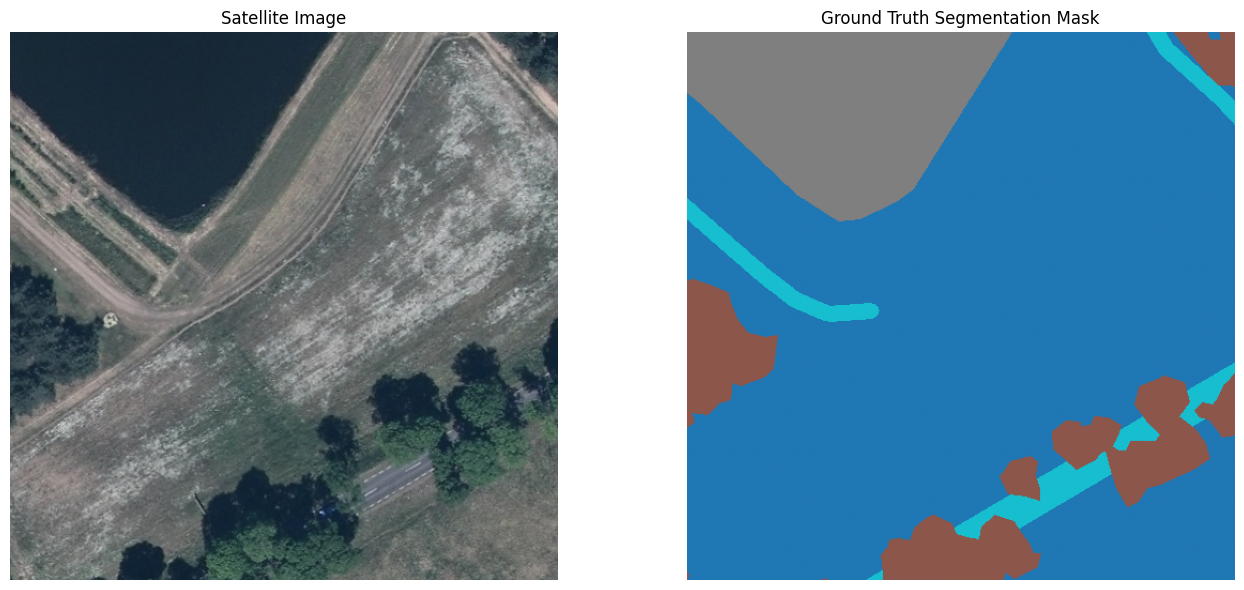

Classes in selected mask:
0: Background
2: Woodlands
3: Water
4: Roads

Train DataLoader drop_last: True
Train dataset size: 7470
Train batch size: 8


In [6]:

import matplotlib.pyplot as plt
import numpy as np
import torch

# ImageNet normalization values used to normalize RGB images
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

# Class names corresponding to mask IDs
CLASS_NAMES = {
    0: "Background",
    1: "Buildings",
    2: "Woodlands",
    3: "Water",
    4: "Roads"
}

# Select the image containing the largest number of classes
unique_counts = [
    len(torch.unique(masks[i]))
    for i in range(len(masks))
]
sample_idx = int(np.argmax(unique_counts))

# Get the selected image and its ground-truth mask
image = images[sample_idx].clone()
mask = masks[sample_idx].clone()

# Reverse ImageNet normalization for visualization
image = image * STD + MEAN
image = image.permute(1, 2, 0).numpy()
image = np.clip(image, 0, 1)

mask = mask.numpy()

# Display image and mask side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(image)
axes[0].set_title("Satellite Image")
axes[0].axis("off")

axes[1].imshow(mask, cmap="tab10", vmin=0, vmax=4)
axes[1].set_title("Ground Truth Segmentation Mask")
axes[1].axis("off")

plt.tight_layout()
plt.show()

# Print the classes present in this sample
print("Classes in selected mask:")
for class_id in np.unique(mask):
    print(f"{class_id}: {CLASS_NAMES[int(class_id)]}")

# Check whether the last incomplete training batch is dropped
print("\nTrain DataLoader drop_last:", train_loader.drop_last)
print("Train dataset size:", len(train_loader.dataset))
print("Train batch size:", train_loader.batch_size)


In [7]:

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet50, ResNet50_Weights


# --------------------------------------------------
# 1. ResNet50 Backbone
# --------------------------------------------------

class ResNet50Backbone(nn.Module):
    def __init__(self, pretrained=True):
        super().__init__()

        # Load ImageNet pretrained weights if requested
        weights = ResNet50_Weights.DEFAULT if pretrained else None

        # Use dilation in the last ResNet stage to get output stride 16
        resnet = resnet50(
            weights=weights,
            replace_stride_with_dilation=[False, False, True]
        )

        # Keep the layers needed for feature extraction
        self.stem = nn.Sequential(
            resnet.conv1,
            resnet.bn1,
            resnet.relu,
            resnet.maxpool
        )

        self.layer1 = resnet.layer1
        self.layer2 = resnet.layer2
        self.layer3 = resnet.layer3
        self.layer4 = resnet.layer4

    def forward(self, x):

        # Extract early spatial features (low-level features)
        x = self.stem(x)
        low_level_features = self.layer1(x)

        # Extract deeper semantic features
        x = self.layer2(low_level_features)
        x = self.layer3(x)
        high_level_features = self.layer4(x)

        return low_level_features, high_level_features


# --------------------------------------------------
# 2. ASPP: Atrous Spatial Pyramid Pooling
# --------------------------------------------------

class ASPP(nn.Module):
    def __init__(self, in_channels, out_channels=256):
        super().__init__()

        # 1x1 convolution branch
        self.branch1 = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

        # Atrous convolution branches with different dilation rates
        self.branch2 = self._make_atrous_branch(in_channels, out_channels, 6)
        self.branch3 = self._make_atrous_branch(in_channels, out_channels, 12)
        self.branch4 = self._make_atrous_branch(in_channels, out_channels, 18)

        # Global average pooling branch
        self.global_pool = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

        # Combine the five branches
        self.project = nn.Sequential(
            nn.Conv2d(out_channels * 5, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5)
        )

    def _make_atrous_branch(self, in_channels, out_channels, dilation):
        return nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=dilation,
                dilation=dilation,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):

        # Get outputs from all five ASPP branches
        size = x.shape[2:]

        branch1 = self.branch1(x)
        branch2 = self.branch2(x)
        branch3 = self.branch3(x)
        branch4 = self.branch4(x)

        # Upsample global context to match feature-map size
        global_features = self.global_pool(x)
        global_features = F.interpolate(
            global_features,
            size=size,
            mode="bilinear",
            align_corners=False
        )

        # Concatenate all branches
        features = torch.cat(
            [branch1, branch2, branch3, branch4, global_features],
            dim=1
        )

        return self.project(features)


# --------------------------------------------------
# 3. DeepLabV3+ Decoder
# --------------------------------------------------

class DeepLabV3Plus(nn.Module):
    def __init__(self, num_classes=5, pretrained=True):
        super().__init__()

        # ResNet50 feature extractor
        self.backbone = ResNet50Backbone(pretrained=pretrained)

        # ResNet50 layer4 produces 2048 channels
        self.aspp = ASPP(in_channels=2048, out_channels=256)

        # Reduce low-level features from 256 to 48 channels
        self.low_level_projection = nn.Sequential(
            nn.Conv2d(256, 48, kernel_size=1, bias=False),
            nn.BatchNorm2d(48),
            nn.ReLU(inplace=True)
        )

        # Decoder combines ASPP and low-level features
        self.decoder = nn.Sequential(
            nn.Conv2d(256 + 48, 256, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),

            nn.Conv2d(256, 256, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True)
        )

        # Predict one score for each of the five classes
        self.classifier = nn.Conv2d(
            256,
            num_classes,
            kernel_size=1
        )

    def forward(self, x):

        input_size = x.shape[2:]

        # Extract low-level and high-level features
        low_features, high_features = self.backbone(x)

        # Apply ASPP to high-level features
        high_features = self.aspp(high_features)

        # Resize ASPP features to match low-level feature size
        high_features = F.interpolate(
            high_features,
            size=low_features.shape[2:],
            mode="bilinear",
            align_corners=False
        )

        # Project low-level features
        low_features = self.low_level_projection(low_features)

        # Combine both feature types
        features = torch.cat(
            [high_features, low_features],
            dim=1
        )

        # Decode combined features
        features = self.decoder(features)

        # Generate class predictions
        output = self.classifier(features)

        # Resize predictions to original image resolution
        output = F.interpolate(
            output,
            size=input_size,
            mode="bilinear",
            align_corners=False
        )

        return output


print("DeepLabV3+ architecture classes defined successfully!")


DeepLabV3+ architecture classes defined successfully!


In [8]:

# Select GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Create the DeepLabV3+ model
model = DeepLabV3Plus(
    num_classes=5,
    pretrained=True
)

# Move the model to GPU
model = model.to(device)

# Get one batch and move it to GPU
sample_images, sample_masks = next(iter(train_loader))
sample_images = sample_images.to(device)

# Run a forward pass without calculating gradients
model.eval()

with torch.no_grad():
    predictions = model(sample_images)

# Display output information
print("Device:", device)
print("Input shape:", sample_images.shape)
print("Output shape:", predictions.shape)
print("Number of parameters:", sum(p.numel() for p in model.parameters()))

# Check output dimensions
assert predictions.shape == (8, 5, 512, 512)

print("\nForward pass successful!")


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 205MB/s]


Device: cuda
Input shape: torch.Size([8, 3, 512, 512])
Output shape: torch.Size([8, 5, 512, 512])
Number of parameters: 40348069

Forward pass successful!


In [9]:

import torch
import torch.nn as nn
import torch.optim as optim

# Number of segmentation classes
NUM_CLASSES = 5

# Move class weights to GPU
class_weights = torch.tensor(
    CLASS_WEIGHTS_SMOOTH,
    dtype=torch.float32
).to(device)

# Cross Entropy Loss for pixel-level classification
criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

# AdamW optimizer updates the model parameters
optimizer = optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

# Reduce learning rate when validation performance stops improving
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)
print("Initial learning rate:", optimizer.param_groups[0]["lr"])
print("Class weights:", class_weights)


Loss function: CrossEntropyLoss()
Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)
Initial learning rate: 0.001
Class weights: tensor([0.2500, 2.0000, 0.3300, 0.7500, 1.4500], device='cuda:0')


In [10]:

import numpy as np

def calculate_metrics(confusion_matrix):
    """
    Calculate per-class IoU and Dice score,
    along with mean IoU and mean Dice.
    """

    # Extract true positives for each class
    true_positive = np.diag(confusion_matrix)

    # Calculate false positives and false negatives
    false_positive = confusion_matrix.sum(axis=0) - true_positive
    false_negative = confusion_matrix.sum(axis=1) - true_positive

    # Calculate IoU for each class
    denominator_iou = true_positive + false_positive + false_negative

    iou = np.divide(
        true_positive,
        denominator_iou,
        out=np.full(NUM_CLASSES, np.nan, dtype=float),
        where=denominator_iou != 0
    )

    # Calculate Dice score for each class
    denominator_dice = 2 * true_positive + false_positive + false_negative

    dice = np.divide(
        2 * true_positive,
        denominator_dice,
        out=np.full(NUM_CLASSES, np.nan, dtype=float),
        where=denominator_dice != 0
    )

    # Ignore classes absent from the evaluated data
    mean_iou = np.nanmean(iou)
    mean_dice = np.nanmean(dice)

    return iou, dice, mean_iou, mean_dice


def update_confusion_matrix(predictions, targets, num_classes=5):
    """
    Build a confusion matrix for semantic segmentation.
    Rows represent true classes and columns represent predicted classes.
    """

    predictions = predictions.reshape(-1).long()
    targets = targets.reshape(-1).long()

    # Encode each true/predicted pair into one index
    encoded = targets * num_classes + predictions

    matrix = torch.bincount(
        encoded,
        minlength=num_classes ** 2
    )

    return matrix.reshape(num_classes, num_classes)


print("Evaluation metrics functions are ready!")


Evaluation metrics functions are ready!


In [11]:

import time
import pandas as pd
import torch
from tqdm.auto import tqdm

# Set the number of epochs for the first training test
NUM_EPOCHS = 1

# Store training history
training_logs = []

# Initialize the best validation score
best_val_miou = 0.0

# Train and validate the model
for epoch in range(NUM_EPOCHS):

    start_time = time.time()

    # -------------------------
    # Training Phase
    # -------------------------
    model.train()
    running_train_loss = 0.0

    train_bar = tqdm(train_loader, desc=f"Epoch {epoch + 1} - Training")

    for images, masks in train_bar:

        images = images.to(device)
        masks = masks.to(device)

        # Clear previous gradients
        optimizer.zero_grad(set_to_none=True)

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, masks)

        # Backpropagation
        loss.backward()

        # Update model parameters
        optimizer.step()

        running_train_loss += loss.item() * images.size(0)

        train_bar.set_postfix(loss=loss.item())

    train_loss = running_train_loss / len(train_loader.dataset)

    # -------------------------
    # Validation Phase
    # -------------------------
    model.eval()
    running_val_loss = 0.0

    confusion_matrix = torch.zeros(
        NUM_CLASSES, NUM_CLASSES,
        dtype=torch.long,
        device=device
    )

    with torch.no_grad():

        val_bar = tqdm(val_loader, desc=f"Epoch {epoch + 1} - Validation")

        for images, masks in val_bar:

            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)
            loss = criterion(outputs, masks)

            running_val_loss += loss.item() * images.size(0)

            predictions = torch.argmax(outputs, dim=1)

            confusion_matrix += update_confusion_matrix(
                predictions, masks, NUM_CLASSES
            )

    val_loss = running_val_loss / len(val_loader.dataset)

    # Calculate validation metrics
    iou, dice, val_miou, val_mdice = calculate_metrics(
        confusion_matrix.cpu().numpy()
    )

    # Update learning rate scheduler
    scheduler.step(val_miou)

    # Calculate epoch duration
    epoch_time = time.time() - start_time

    # Save training history
    training_logs.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_miou": val_miou,
        "val_mdice": val_mdice,
        "training_time_seconds": epoch_time
    })

    # Save the best model checkpoint
    if val_miou > best_val_miou:

        best_val_miou = val_miou

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_miou": val_miou
        }, "/kaggle/working/deeplabv3plus_best.pth")

    # Print epoch results
    print(f"\nEpoch {epoch + 1}/{NUM_EPOCHS}")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation mIoU: {val_miou:.4f}")
    print(f"Validation Dice: {val_mdice:.4f}")
    print(f"Epoch Time: {epoch_time / 60:.2f} minutes")

# Save training logs
pd.DataFrame(training_logs).to_csv(
    "/kaggle/working/training_logs.csv",
    index=False
)

print("\nTraining test completed!")
print("Best Validation mIoU:", best_val_miou)


Epoch 1 - Training:   0%|          | 0/933 [00:00<?, ?it/s]

Epoch 1 - Validation:   0%|          | 0/201 [00:00<?, ?it/s]


Epoch 1/1
Train Loss: 0.6474
Validation Loss: 0.4053
Validation mIoU: 0.5669
Validation Dice: 0.6941
Epoch Time: 18.78 minutes

Training test completed!
Best Validation mIoU: 0.5668751467891495


In [12]:
# Save the current model checkpoint
torch.save({
    "epoch": 1,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "scheduler_state_dict": scheduler.state_dict(),
    "best_val_miou": best_val_miou
}, "/kaggle/working/deeplabv3plus_resume.pth")

print("Checkpoint saved successfully!")

Checkpoint saved successfully!


In [13]:

import time
import pandas as pd
import torch
from tqdm.auto import tqdm

# Load the latest checkpoint
checkpoint = torch.load(
    "/kaggle/working/deeplabv3plus_resume.pth",
    map_location=device,
    weights_only=False
)

# Restore model, optimizer, and scheduler states
model.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
scheduler.load_state_dict(checkpoint["scheduler_state_dict"])

# Resume from the next epoch
start_epoch = int(checkpoint["epoch"])
best_val_miou = float(checkpoint["best_val_miou"])

# Load previous training logs
training_logs = pd.read_csv(
    "/kaggle/working/training_logs.csv"
).to_dict("records")

# Train for five additional epochs
ADDITIONAL_EPOCHS = 5

for epoch in range(start_epoch, start_epoch + ADDITIONAL_EPOCHS):

    start_time = time.time()

    # -------------------------
    # Training Phase
    # -------------------------
    model.train()
    running_train_loss = 0.0

    train_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1} - Training"
    )

    for images, masks in train_bar:

        images = images.to(device)
        masks = masks.to(device)

        # Clear previous gradients
        optimizer.zero_grad(set_to_none=True)

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, masks)

        # Backpropagation
        loss.backward()

        # Update model parameters
        optimizer.step()

        running_train_loss += loss.item() * images.size(0)
        train_bar.set_postfix(loss=loss.item())

    train_loss = running_train_loss / len(train_loader.dataset)

    # -------------------------
    # Validation Phase
    # -------------------------
    model.eval()
    running_val_loss = 0.0

    confusion_matrix = torch.zeros(
        NUM_CLASSES,
        NUM_CLASSES,
        dtype=torch.long,
        device=device
    )

    with torch.no_grad():

        val_bar = tqdm(
            val_loader,
            desc=f"Epoch {epoch + 1} - Validation"
        )

        for images, masks in val_bar:

            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)
            loss = criterion(outputs, masks)

            running_val_loss += loss.item() * images.size(0)

            predictions = torch.argmax(outputs, dim=1)

            confusion_matrix += update_confusion_matrix(
                predictions,
                masks,
                NUM_CLASSES
            )

    val_loss = running_val_loss / len(val_loader.dataset)

    # Calculate validation metrics
    iou, dice, val_miou, val_mdice = calculate_metrics(
        confusion_matrix.cpu().numpy()
    )

    # Update learning rate scheduler
    scheduler.step(val_miou)

    # Calculate epoch duration
    epoch_time = time.time() - start_time

    # Record epoch results
    training_logs.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_miou": val_miou,
        "val_mdice": val_mdice,
        "training_time_seconds": epoch_time
    })

    # Save the best model checkpoint
    if val_miou > best_val_miou:

        best_val_miou = float(val_miou)

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_miou": float(val_miou)
        }, "/kaggle/working/deeplabv3plus_best.pth")

    # Save the latest checkpoint for resuming
    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "best_val_miou": float(best_val_miou)
    }, "/kaggle/working/deeplabv3plus_resume.pth")

    # Save updated training logs
    pd.DataFrame(training_logs).to_csv(
        "/kaggle/working/training_logs.csv",
        index=False
    )

    # Print epoch results
    print(f"\nEpoch {epoch + 1}")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation mIoU: {val_miou:.4f}")
    print(f"Validation Dice: {val_mdice:.4f}")
    print(f"Epoch Time: {epoch_time / 60:.2f} minutes")
    print(f"Best Validation mIoU: {best_val_miou:.4f}")

print("\nAdditional training completed!")
print("Total completed epochs:", start_epoch + ADDITIONAL_EPOCHS)
print("Best Validation mIoU:", best_val_miou)


Epoch 2 - Training:   0%|          | 0/933 [00:00<?, ?it/s]

Epoch 2 - Validation:   0%|          | 0/201 [00:00<?, ?it/s]


Epoch 2
Train Loss: 0.4946
Validation Loss: 0.3100
Validation mIoU: 0.6390
Validation Dice: 0.7549
Epoch Time: 18.85 minutes
Best Validation mIoU: 0.6390


Epoch 3 - Training:   0%|          | 0/933 [00:00<?, ?it/s]

Epoch 3 - Validation:   0%|          | 0/201 [00:00<?, ?it/s]


Epoch 3
Train Loss: 0.4035
Validation Loss: 0.2766
Validation mIoU: 0.6860
Validation Dice: 0.7985
Epoch Time: 18.85 minutes
Best Validation mIoU: 0.6860


... (5 outputs left out)


Epoch 5
Train Loss: 0.3326
Validation Loss: 0.2598
Validation mIoU: 0.6942
Validation Dice: 0.8059
Epoch Time: 18.85 minutes
Best Validation mIoU: 0.6942


Epoch 6 - Training:   0%|          | 0/933 [00:00<?, ?it/s]

Epoch 6 - Validation:   0%|          | 0/201 [00:00<?, ?it/s]


Epoch 6
Train Loss: 0.3065
Validation Loss: 0.2373
Validation mIoU: 0.7226
Validation Dice: 0.8291
Epoch Time: 18.85 minutes
Best Validation mIoU: 0.7226

Additional training completed!
Total completed epochs: 6
Best Validation mIoU: 0.7225667959353681


In [14]:

import numpy as np
import pandas as pd
import torch

# Load the best model checkpoint
best_checkpoint = torch.load(
    "/kaggle/working/deeplabv3plus_best.pth",
    map_location=device,
    weights_only=False
)

model.load_state_dict(best_checkpoint["model_state_dict"])
model.eval()

# Define the class names
CLASS_NAMES = [
    "Background",
    "Buildings",
    "Woodlands",
    "Water",
    "Roads"
]

# Initialize the confusion matrix
confusion_matrix = torch.zeros(
    NUM_CLASSES,
    NUM_CLASSES,
    dtype=torch.long,
    device=device
)

# Evaluate the best model on the validation set
with torch.no_grad():

    for images, masks in val_loader:

        images = images.to(device)
        masks = masks.to(device)

        outputs = model(images)
        predictions = torch.argmax(outputs, dim=1)

        confusion_matrix += update_confusion_matrix(
            predictions,
            masks,
            NUM_CLASSES
        )

# Calculate per-class metrics
iou, dice, mean_iou, mean_dice = calculate_metrics(
    confusion_matrix.cpu().numpy()
)

# Create a results table
per_class_results = pd.DataFrame({
    "Class": CLASS_NAMES,
    "IoU": iou,
    "Dice": dice
})

# Display results as percentages
per_class_results["IoU"] *= 100
per_class_results["Dice"] *= 100

print("Per-Class Evaluation Results:")
display(per_class_results.round(2))

print(f"\nMean IoU: {mean_iou * 100:.2f}%")
print(f"Mean Dice: {mean_dice * 100:.2f}%")

# Save per-class results
per_class_results.to_csv(
    "/kaggle/working/per_class_results.csv",
    index=False
)

print("\nPer-class results saved successfully!")


Per-Class Evaluation Results:


,Class,IoU,Dice
0,Background,88.09,93.67
1,Buildings,58.90,74.14
2,Woodlands,84.77,91.76
3,Water,80.53,89.22
4,Roads,48.98,65.75



Mean IoU: 72.26%
Mean Dice: 82.91%

Per-class results saved successfully!


In [15]:

import torch
import torch.nn as nn

# Create a fresh DeepLabV3+ model
ablation_model = DeepLabV3Plus(
    num_classes=NUM_CLASSES,
    pretrained=True
)

# Replace ASPP with a simple 1x1 convolution
# This removes multi-scale atrous feature extraction
ablation_model.aspp = nn.Sequential(
    nn.Conv2d(
        in_channels=2048,
        out_channels=256,
        kernel_size=1,
        bias=False
    ),
    nn.BatchNorm2d(256),
    nn.ReLU(inplace=True)
)

# Move the ablation model to GPU
ablation_model = ablation_model.to(device)

# Test the modified model
ablation_model.eval()

sample_images, sample_masks = next(iter(val_loader))
sample_images = sample_images.to(device)

with torch.no_grad():
    sample_outputs = ablation_model(sample_images)

print("Ablation model created successfully!")
print("Input shape:", sample_images.shape)
print("Output shape:", sample_outputs.shape)
print(
    "Number of parameters:",
    sum(p.numel() for p in ablation_model.parameters())
)


Ablation model created successfully!
Input shape: torch.Size([8, 3, 512, 512])
Output shape: torch.Size([8, 5, 512, 512])
Number of parameters: 25337765


In [16]:
import time
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

# Define the loss function
ablation_criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

# Define the optimizer
ablation_optimizer = optim.AdamW(
    ablation_model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

# Define the learning rate scheduler
ablation_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    ablation_optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

# Store training history
ablation_history = []

best_ablation_miou = 0.0
NUM_EPOCHS = 6

for epoch in range(NUM_EPOCHS):

    start_time = time.time()

    # Training phase
    ablation_model.train()
    train_loss = 0.0

    for images, masks in train_loader:

        images = images.to(device)
        masks = masks.to(device)

        ablation_optimizer.zero_grad()

        outputs = ablation_model(images)
        loss = ablation_criterion(outputs, masks)

        loss.backward()
        ablation_optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)

    # Validation phase
    ablation_model.eval()

    val_loss = 0.0
    confusion_matrix = torch.zeros(
        NUM_CLASSES, NUM_CLASSES,
        dtype=torch.int64,
        device=device
    )

    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(device)
            masks = masks.to(device)

            outputs = ablation_model(images)
            loss = ablation_criterion(outputs, masks)

            val_loss += loss.item()

            predictions = torch.argmax(outputs, dim=1)

            confusion_matrix += update_confusion_matrix(
                predictions,
                masks,
                NUM_CLASSES
            ).to(device)

    val_loss /= len(val_loader)

    # Calculate validation metrics
    iou, dice, val_miou, val_dice = calculate_metrics(
        confusion_matrix.cpu().numpy()
    )

    ablation_scheduler.step(val_miou)

    epoch_time = (time.time() - start_time) / 60

    # Save epoch results
    ablation_history.append({
        "Epoch": epoch + 1,
        "Train Loss": train_loss,
        "Val Loss": val_loss,
        "Val mIoU": val_miou,
        "Val Dice": val_dice,
        "Time (min)": epoch_time
    })

    print(f"\nEpoch [{epoch+1}/{NUM_EPOCHS}]")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation mIoU: {val_miou:.4f}")
    print(f"Validation Dice: {val_dice:.4f}")
    print(f"Time: {epoch_time:.2f} minutes")

    # Save the best ablation checkpoint
    if val_miou > best_ablation_miou:

        best_ablation_miou = val_miou

        torch.save(
            ablation_model.state_dict(),
            "/kaggle/working/deeplabv3plus_ablation_best.pth"
        )

        print("Best ablation model saved!")

    # Save training history after every epoch
    pd.DataFrame(ablation_history).to_csv(
        "/kaggle/working/ablation_training_logs.csv",
        index=False
    )

print("\nAblation training completed!")
print("Best Validation mIoU:", best_ablation_miou)


Epoch [1/6]
Train Loss: 0.5563
Validation Loss: 0.3591
Validation mIoU: 0.6446
Validation Dice: 0.7697
Time: 14.82 minutes
Best ablation model saved!

Epoch [2/6]
Train Loss: 0.4117
Validation Loss: 0.2973
Validation mIoU: 0.6952
Validation Dice: 0.8093
Time: 14.83 minutes
Best ablation model saved!

Epoch [3/6]
Train Loss: 0.3238
Validation Loss: 0.2471
Validation mIoU: 0.7138
Validation Dice: 0.8209
Time: 14.83 minutes
Best ablation model saved!

Epoch [4/6]
Train Loss: 0.3037
Validation Loss: 0.2548
Validation mIoU: 0.6994
Validation Dice: 0.8066
Time: 14.82 minutes

Epoch [5/6]
Train Loss: 0.2934
Validation Loss: 0.2245
Validation mIoU: 0.7154
Validation Dice: 0.8194
Time: 14.82 minutes
Best ablation model saved!

Epoch [6/6]
Train Loss: 0.2678
Validation Loss: 0.2247
Validation mIoU: 0.7333
Validation Dice: 0.8396
Time: 14.81 minutes
Best ablation model saved!

Ablation training completed!
Best Validation mIoU: 0.7333209997097934


In [17]:
import torch
import pandas as pd
import numpy as np

# Load the best ablation checkpoint
ablation_model.load_state_dict(
    torch.load(
        "/kaggle/working/deeplabv3plus_ablation_best.pth",
        map_location=device,
        weights_only=True
    )
)

ablation_model.eval()

# Initialize confusion matrix
ablation_confusion_matrix = torch.zeros(
    NUM_CLASSES,
    NUM_CLASSES,
    dtype=torch.int64,
    device=device
)

# Evaluate on validation set
with torch.no_grad():

    for images, masks in val_loader:

        images = images.to(device)
        masks = masks.to(device)

        outputs = ablation_model(images)
        predictions = torch.argmax(outputs, dim=1)

        ablation_confusion_matrix += update_confusion_matrix(
            predictions,
            masks,
            NUM_CLASSES
        ).to(device)

# Calculate per-class metrics
ablation_iou, ablation_dice, ablation_miou, ablation_mdice = calculate_metrics(
    ablation_confusion_matrix.cpu().numpy()
)

# Create results table
class_names = [
    "Background",
    "Buildings",
    "Woodlands",
    "Water",
    "Roads"
]

ablation_results = pd.DataFrame({
    "Class": class_names,
    "IoU": ablation_iou,
    "Dice": ablation_dice
})

# Save results
ablation_results.to_csv(
    "/kaggle/working/ablation_per_class_results.csv",
    index=False
)

print("Ablation Per-Class Results:")
display(
    ablation_results.style.format({
        "IoU": "{:.2%}",
        "Dice": "{:.2%}"
    })
)

print(f"Mean IoU: {ablation_miou:.2%}")
print(f"Mean Dice: {ablation_mdice:.2%}")

Ablation Per-Class Results:


,Class,IoU,Dice
0,Background,87.81%,93.51%
1,Buildings,61.62%,76.26%
2,Woodlands,85.38%,92.12%
3,Water,76.70%,86.81%
4,Roads,55.15%,71.09%


Mean IoU: 73.33%
Mean Dice: 83.96%


In [18]:
import pandas as pd

# Define full model results
full_iou = [0.8784, 0.4263, 0.8536, 0.8404, 0.4631]
full_dice = [0.9352, 0.5978, 0.9210, 0.9133, 0.6331]

# Create comparison table
comparison_df = pd.DataFrame({
    "Class": class_names,
    "Full_Model_IoU": full_iou,
    "Ablation_IoU": ablation_iou,
    "Full_Model_Dice": full_dice,
    "Ablation_Dice": ablation_dice
})

# Calculate the difference in percentage points
comparison_df["IoU_Difference"] = (
    comparison_df["Ablation_IoU"] -
    comparison_df["Full_Model_IoU"]
) * 100

comparison_df["Dice_Difference"] = (
    comparison_df["Ablation_Dice"] -
    comparison_df["Full_Model_Dice"]
) * 100

# Save comparison results
comparison_df.to_csv(
    "/kaggle/working/ablation_comparison.csv",
    index=False
)

display(
    comparison_df.style.format({
        "Full_Model_IoU": "{:.2%}",
        "Ablation_IoU": "{:.2%}",
        "Full_Model_Dice": "{:.2%}",
        "Ablation_Dice": "{:.2%}",
        "IoU_Difference": "{:+.2f}",
        "Dice_Difference": "{:+.2f}"
    })
)

print("Ablation comparison saved successfully!")

,Class,Full_Model_IoU,Ablation_IoU,Full_Model_Dice,Ablation_Dice,IoU_Difference,Dice_Difference
0,Background,87.84%,87.81%,93.52%,93.51%,-0.03,-0.01
1,Buildings,42.63%,61.62%,59.78%,76.26%,+18.99,+16.48
2,Woodlands,85.36%,85.38%,92.10%,92.12%,+0.02,+0.02
3,Water,84.04%,76.70%,91.33%,86.81%,-7.34,-4.52
4,Roads,46.31%,55.15%,63.31%,71.09%,+8.84,+7.78


Ablation comparison saved successfully!


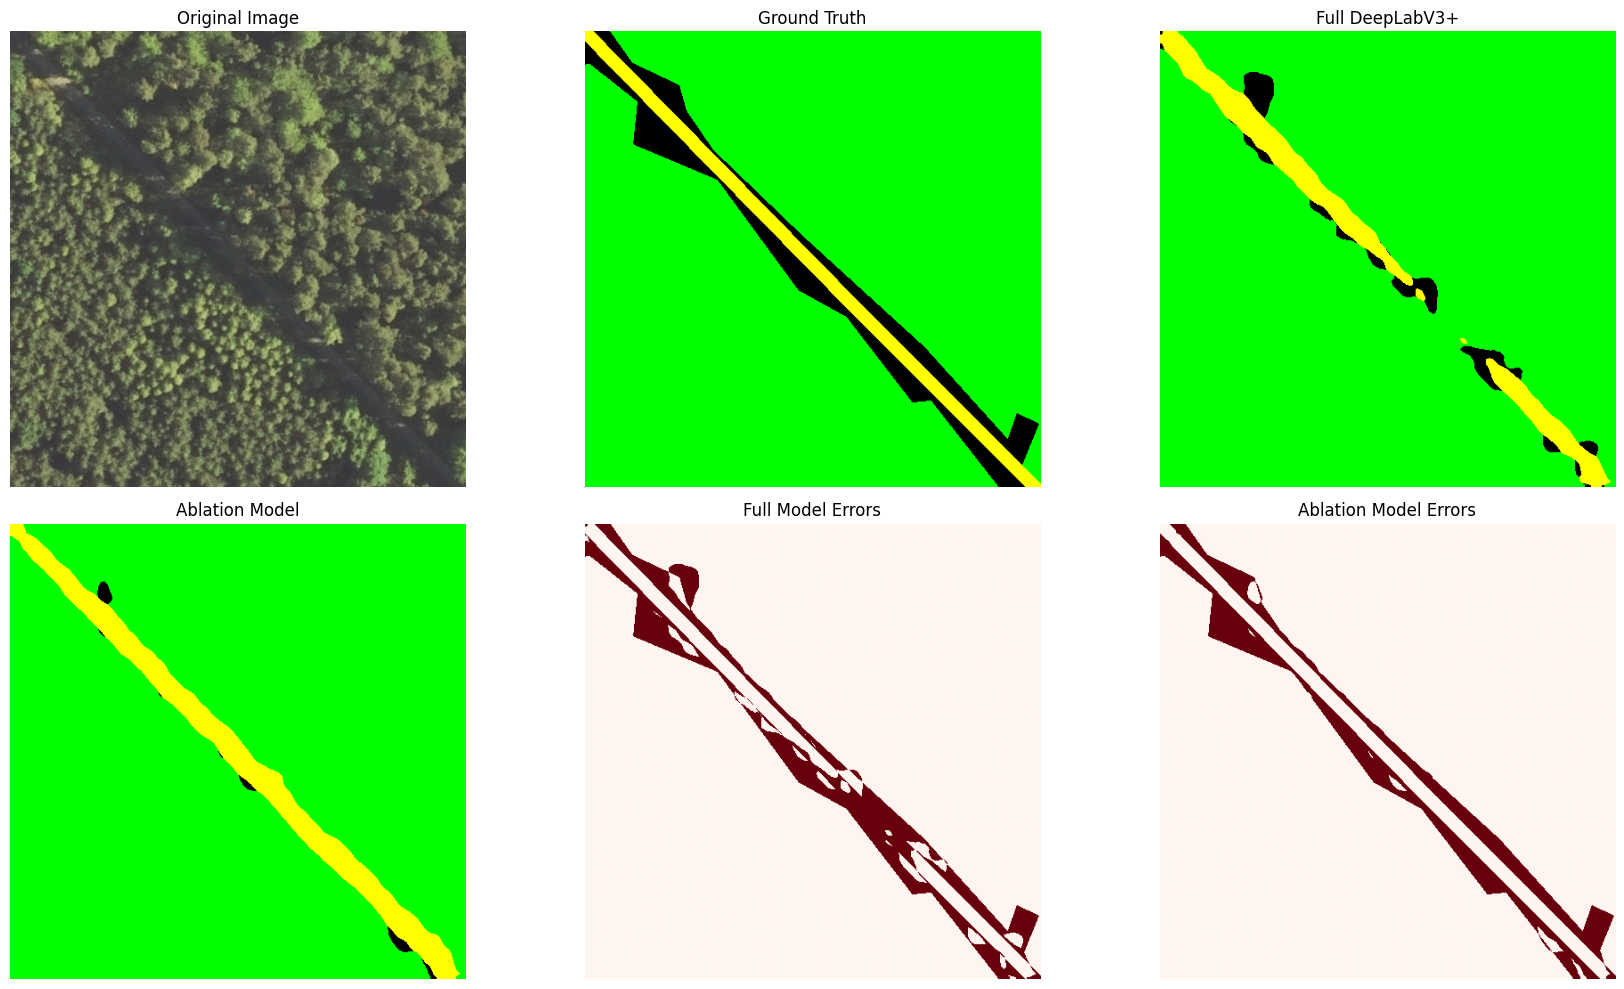

In [19]:
import matplotlib.pyplot as plt
import torch
import numpy as np

# Define class names and visualization colors
class_names = [
    "Background",
    "Buildings",
    "Woodlands",
    "Water",
    "Roads"
]

colors = [
    [0, 0, 0],
    [1, 0, 0],
    [0, 1, 0],
    [0, 0, 1],
    [1, 1, 0]
]

# Get one validation batch
images, masks = next(iter(val_loader))

images = images.to(device)
masks = masks.to(device)

# Generate predictions from both models
model.eval()
ablation_model.eval()

with torch.no_grad():

    full_outputs = model(images)
    ablation_outputs = ablation_model(images)

    full_predictions = torch.argmax(full_outputs, dim=1)
    ablation_predictions = torch.argmax(ablation_outputs, dim=1)

# Select one sample
sample_idx = 0

image = images[sample_idx].cpu().numpy()
ground_truth = masks[sample_idx].cpu().numpy()
full_pred = full_predictions[sample_idx].cpu().numpy()
ablation_pred = ablation_predictions[sample_idx].cpu().numpy()

# Convert normalized image to display format
mean = np.array([0.485, 0.456, 0.406]).reshape(3, 1, 1)
std = np.array([0.229, 0.224, 0.225]).reshape(3, 1, 1)

image = image * std + mean
image = np.clip(image.transpose(1, 2, 0), 0, 1)

# Convert segmentation masks to RGB
def colorize_mask(mask):
    rgb = np.zeros((*mask.shape, 3))

    for class_id, color in enumerate(colors):
        rgb[mask == class_id] = color

    return rgb

# Generate error maps
full_errors = (full_pred != ground_truth)
ablation_errors = (ablation_pred != ground_truth)

# Plot results
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

axes[0, 0].imshow(image)
axes[0, 0].set_title("Original Image")

axes[0, 1].imshow(colorize_mask(ground_truth))
axes[0, 1].set_title("Ground Truth")

axes[0, 2].imshow(colorize_mask(full_pred))
axes[0, 2].set_title("Full DeepLabV3+")

axes[1, 0].imshow(colorize_mask(ablation_pred))
axes[1, 0].set_title("Ablation Model")

axes[1, 1].imshow(full_errors, cmap="Reds")
axes[1, 1].set_title("Full Model Errors")

axes[1, 2].imshow(ablation_errors, cmap="Reds")
axes[1, 2].set_title("Ablation Model Errors")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.savefig(
    "/kaggle/working/ablation_error_analysis.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

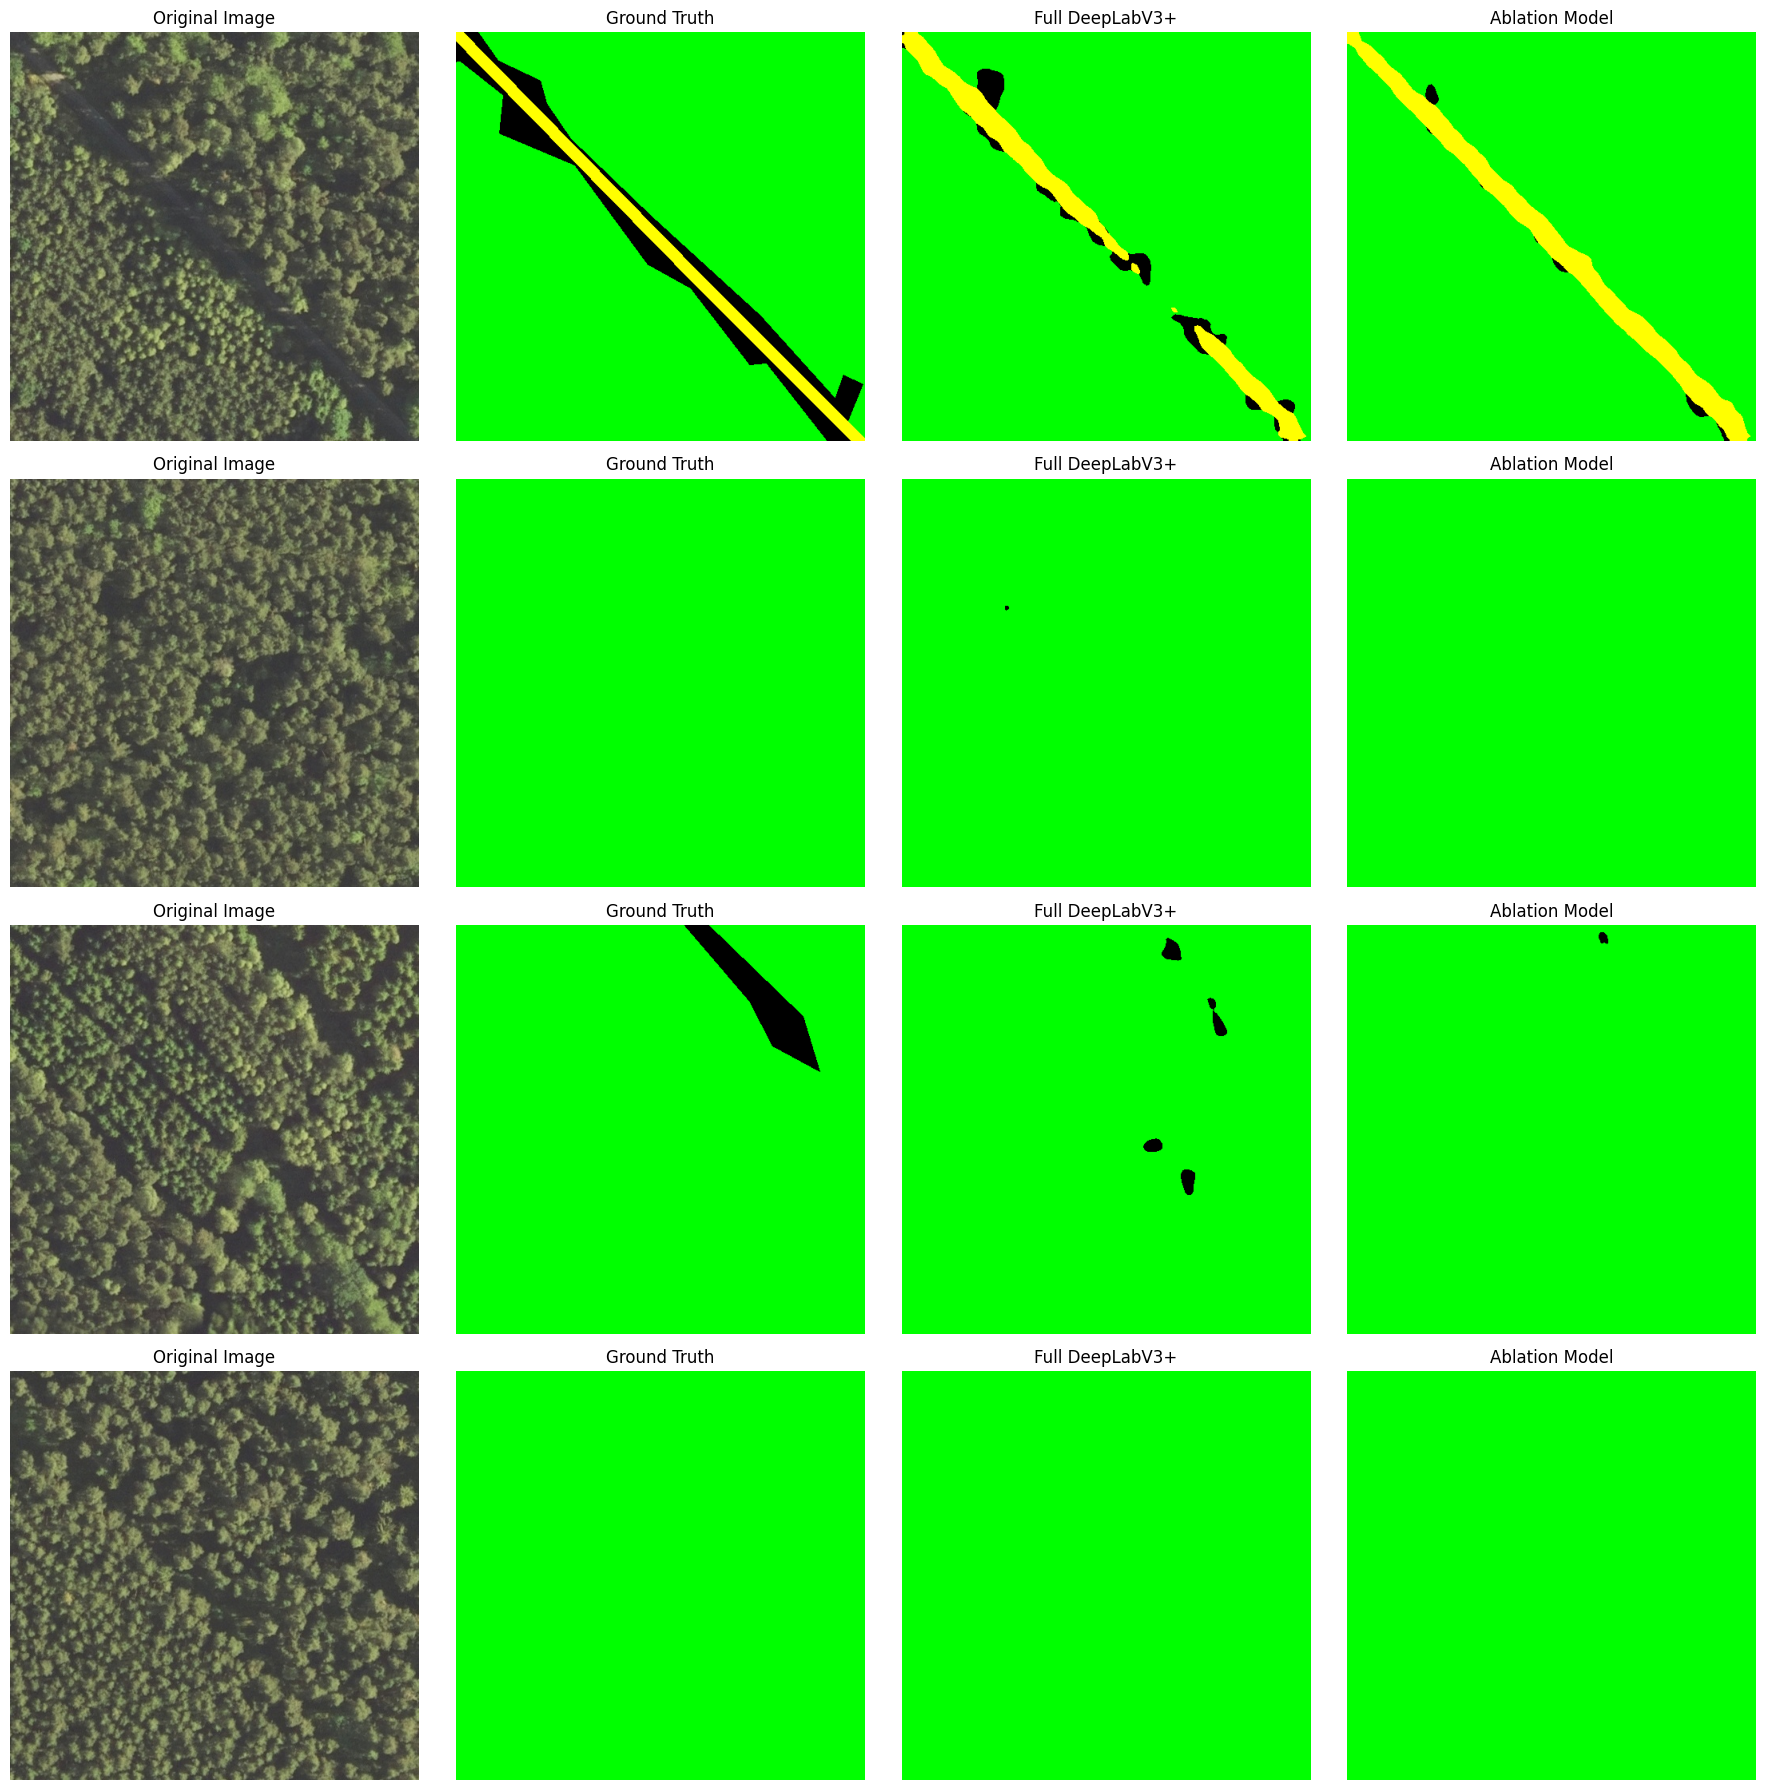

In [20]:
import matplotlib.pyplot as plt
import numpy as np
import torch

# Select four validation samples
images, masks = next(iter(val_loader))

images = images.to(device)
masks = masks.to(device)

# Generate predictions
model.eval()
ablation_model.eval()

with torch.no_grad():
    full_predictions = torch.argmax(model(images), dim=1)
    ablation_predictions = torch.argmax(ablation_model(images), dim=1)

# Convert normalized images to display format
mean = np.array([0.485, 0.456, 0.406]).reshape(3, 1, 1)
std = np.array([0.229, 0.224, 0.225]).reshape(3, 1, 1)

def denormalize(image):
    image = image.cpu().numpy()
    image = image * std + mean
    return np.clip(image.transpose(1, 2, 0), 0, 1)

# Display four samples
fig, axes = plt.subplots(4, 4, figsize=(18, 18))

for i in range(4):

    original = denormalize(images[i])
    ground_truth = masks[i].cpu().numpy()
    full_pred = full_predictions[i].cpu().numpy()
    ablation_pred = ablation_predictions[i].cpu().numpy()

    axes[i, 0].imshow(original)
    axes[i, 0].set_title("Original Image")

    axes[i, 1].imshow(colorize_mask(ground_truth))
    axes[i, 1].set_title("Ground Truth")

    axes[i, 2].imshow(colorize_mask(full_pred))
    axes[i, 2].set_title("Full DeepLabV3+")

    axes[i, 3].imshow(colorize_mask(ablation_pred))
    axes[i, 3].set_title("Ablation Model")

    for j in range(4):
        axes[i, j].axis("off")

plt.tight_layout()
plt.savefig(
    "/kaggle/working/multiple_error_analysis.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

In [21]:
import os

# Check saved model checkpoints
checkpoint_files = [
    "deeplabv3plus_best.pth",
    "deeplabv3plus_ablation_best.pth"
]

for filename in checkpoint_files:

    filepath = f"/kaggle/working/{filename}"

    if os.path.exists(filepath):
        size_mb = os.path.getsize(filepath) / (1024 ** 2)

        print(f"[FOUND] {filename}")
        print(f"Size: {size_mb:.2f} MB")

    else:
        print(f"[MISSING] {filename}")

[FOUND] deeplabv3plus_best.pth
Size: 462.25 MB
[FOUND] deeplabv3plus_ablation_best.pth
Size: 96.98 MB


In [22]:

import torch
import pandas as pd
import numpy as np
import time
from collections import OrderedDict

# ==========================================
# 1. Check required variables
# ==========================================

required_variables = [
    "model",
    "ablation_model",
    "device",
    "NUM_CLASSES",
    "test_loader",
    "criterion"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        f"Missing required variables: {missing_variables}. "
        "Run the model and data preparation cells first."
    )

print("All required variables are available.")


# ==========================================
# 2. Load checkpoint safely
# ==========================================

def extract_model_weights(checkpoint, checkpoint_name):

    if not isinstance(checkpoint, (dict, OrderedDict)):
        raise TypeError(
            f"{checkpoint_name} is not a valid checkpoint dictionary."
        )

    # Check common checkpoint formats
    possible_keys = [
        "model_state_dict",
        "state_dict",
        "model"
    ]

    for key in possible_keys:
        if key in checkpoint:
            weights = checkpoint[key]

            if isinstance(weights, (dict, OrderedDict)):
                print(
                    f"{checkpoint_name}: weights found under '{key}'."
                )
                return weights

    # Check if the checkpoint is already a state_dict
    if all(
        isinstance(value, torch.Tensor)
        for value in checkpoint.values()
    ):
        print(
            f"{checkpoint_name}: direct state_dict detected."
        )
        return checkpoint

    raise ValueError(
        f"Could not identify model weights in {checkpoint_name}. "
        f"Available keys: {list(checkpoint.keys())[:15]}"
    )


# Load Full DeepLabV3+ checkpoint
full_checkpoint = torch.load(
    "/kaggle/working/deeplabv3plus_best.pth",
    map_location=device,
    weights_only=True
)

full_weights = extract_model_weights(
    full_checkpoint,
    "Full DeepLabV3+"
)

model.load_state_dict(full_weights)


# Load Ablation checkpoint
ablation_checkpoint = torch.load(
    "/kaggle/working/deeplabv3plus_ablation_best.pth",
    map_location=device,
    weights_only=True
)

ablation_weights = extract_model_weights(
    ablation_checkpoint,
    "Ablation DeepLabV3+"
)

ablation_model.load_state_dict(ablation_weights)


# Set models to evaluation mode
model.to(device)
ablation_model.to(device)

model.eval()
ablation_model.eval()

print("\nBoth models loaded successfully!")


# ==========================================
# 3. Define metrics calculation
# ==========================================

def calculate_metrics(confusion_matrix):

    true_positive = np.diag(confusion_matrix)

    false_positive = (
        confusion_matrix.sum(axis=0) - true_positive
    )

    false_negative = (
        confusion_matrix.sum(axis=1) - true_positive
    )

    denominator_iou = (
        true_positive + false_positive + false_negative
    )

    iou = np.divide(
        true_positive,
        denominator_iou,
        out=np.full(NUM_CLASSES, np.nan, dtype=float),
        where=denominator_iou != 0
    )

    denominator_dice = (
        2 * true_positive + false_positive + false_negative
    )

    dice = np.divide(
        2 * true_positive,
        denominator_dice,
        out=np.full(NUM_CLASSES, np.nan, dtype=float),
        where=denominator_dice != 0
    )

    mean_iou = np.nanmean(iou)
    mean_dice = np.nanmean(dice)

    return iou, dice, mean_iou, mean_dice


# ==========================================
# 4. Define confusion matrix update
# ==========================================

def update_confusion_matrix(
    predictions,
    targets,
    num_classes=5
):

    predictions = predictions.reshape(-1).long()
    targets = targets.reshape(-1).long()

    encoded = targets * num_classes + predictions

    matrix = torch.bincount(
        encoded,
        minlength=num_classes ** 2
    )

    return matrix.reshape(num_classes, num_classes)


# ==========================================
# 5. Evaluate one model on the test set
# ==========================================

def evaluate_on_test(model_to_evaluate, model_name):

    model_to_evaluate.eval()

    confusion_matrix = torch.zeros(
        NUM_CLASSES,
        NUM_CLASSES,
        dtype=torch.int64,
        device=device
    )

    total_loss = 0.0
    total_batches = 0

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start_time = time.time()

    with torch.no_grad():

        for images, masks in test_loader:

            images = images.to(device)
            masks = masks.to(device)

            outputs = model_to_evaluate(images)

            loss = criterion(outputs, masks)

            total_loss += loss.item()
            total_batches += 1

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            confusion_matrix += update_confusion_matrix(
                predictions,
                masks,
                NUM_CLASSES
            ).to(device)

    if total_batches == 0:
        raise RuntimeError("The test_loader contains no batches.")

    total_loss /= total_batches

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    evaluation_time = (
        time.time() - start_time
    ) / 60

    # Calculate final test metrics
    iou, dice, mean_iou, mean_dice = calculate_metrics(
        confusion_matrix.cpu().numpy()
    )

    print(f"\n{model_name}")
    print("-" * 45)
    print(f"Test Loss: {total_loss:.4f}")
    print(f"Test mIoU: {mean_iou:.4f} ({mean_iou:.2%})")
    print(f"Test Dice: {mean_dice:.4f} ({mean_dice:.2%})")
    print(f"Evaluation Time: {evaluation_time:.2f} minutes")

    return {
        "Model": model_name,
        "Test Loss": total_loss,
        "Test mIoU": mean_iou,
        "Test Dice": mean_dice,
        "IoU Per Class": iou,
        "Dice Per Class": dice,
        "Evaluation Time (min)": evaluation_time
    }


# ==========================================
# 6. Evaluate both models on the same test set
# ==========================================

print("\nStarting Final Test Evaluation...")

full_test_results = evaluate_on_test(
    model,
    "Full DeepLabV3+"
)

ablation_test_results = evaluate_on_test(
    ablation_model,
    "Ablation DeepLabV3+"
)


# ==========================================
# 7. Create overall comparison table
# ==========================================

test_comparison = pd.DataFrame([
    {
        "Model": full_test_results["Model"],
        "Test Loss": full_test_results["Test Loss"],
        "Test mIoU": full_test_results["Test mIoU"],
        "Test Dice": full_test_results["Test Dice"],
        "Evaluation Time (min)": (
            full_test_results["Evaluation Time (min)"]
        )
    },
    {
        "Model": ablation_test_results["Model"],
        "Test Loss": ablation_test_results["Test Loss"],
        "Test mIoU": ablation_test_results["Test mIoU"],
        "Test Dice": ablation_test_results["Test Dice"],
        "Evaluation Time (min)": (
            ablation_test_results["Evaluation Time (min)"]
        )
    }
])

print("\nFinal Test Comparison:")
display(test_comparison)


# ==========================================
# 8. Create per-class comparison table
# ==========================================

class_names = [
    "Background",
    "Buildings",
    "Woodlands",
    "Water",
    "Roads"
]

per_class_test_results = pd.DataFrame({
    "Class": class_names,

    "Full IoU": full_test_results["IoU Per Class"],
    "Ablation IoU": ablation_test_results["IoU Per Class"],

    "Full Dice": full_test_results["Dice Per Class"],
    "Ablation Dice": ablation_test_results["Dice Per Class"]
})

print("\nPer-Class Test Results:")
display(per_class_test_results)


# ==========================================
# 9. Save final test results
# ==========================================

test_comparison.to_csv(
    "/kaggle/working/deeplabv3plus_test_comparison.csv",
    index=False
)

per_class_test_results.to_csv(
    "/kaggle/working/deeplabv3plus_test_per_class.csv",
    index=False
)


# ==========================================
# 10. Final confirmation
# ==========================================

print("\n" + "=" * 50)
print("FINAL TEST EVALUATION COMPLETED SUCCESSFULLY!")
print("=" * 50)

print("\nSaved files:")
print("1. deeplabv3plus_test_comparison.csv")
print("2. deeplabv3plus_test_per_class.csv")


All required variables are available.
Full DeepLabV3+: weights found under 'model_state_dict'.
Ablation DeepLabV3+: direct state_dict detected.

Both models loaded successfully!

Starting Final Test Evaluation...

Full DeepLabV3+
---------------------------------------------
Test Loss: 0.2567
Test mIoU: 0.7135 (71.35%)
Test Dice: 0.8227 (82.27%)
Evaluation Time: 1.22 minutes

Ablation DeepLabV3+
---------------------------------------------
Test Loss: 0.2344
Test mIoU: 0.7324 (73.24%)
Test Dice: 0.8385 (83.85%)
Evaluation Time: 0.93 minutes

Final Test Comparison:


,Model,Test Loss,Test mIoU,Test Dice,Evaluation Time (min)
0,Full DeepLabV3+,0.256662,0.713517,0.822674,1.217323
1,Ablation DeepLabV3+,0.234406,0.732365,0.838533,0.934312



Per-Class Test Results:


,Class,Full IoU,Ablation IoU,Full Dice,Ablation Dice
0,Background,0.868714,0.870320,0.929745,0.930664
1,Buildings,0.575665,0.612372,0.730694,0.759591
2,Woodlands,0.855869,0.861746,0.922338,0.925740
3,Water,0.784080,0.774412,0.878974,0.872866
4,Roads,0.483258,0.542973,0.651617,0.703801



FINAL TEST EVALUATION COMPLETED SUCCESSFULLY!

Saved files:
1. deeplabv3plus_test_comparison.csv
2. deeplabv3plus_test_per_class.csv


In [23]:

import os

files_to_check = [
    "/kaggle/working/deeplabv3plus_full_weights.pth",
    "/kaggle/working/deeplabv3plus_model_info.json",
    "/kaggle/working/deeplabv3plus_best.pth"
]

for file_path in files_to_check:

    print("\nFile:", os.path.basename(file_path))

    if os.path.exists(file_path):
        size_mb = os.path.getsize(file_path) / (1024 ** 2)
        print("Status: EXISTS")
        print(f"Size: {size_mb:.2f} MB")
    else:
        print("Status: NOT FOUND")



File: deeplabv3plus_full_weights.pth
Status: NOT FOUND

File: deeplabv3plus_model_info.json
Status: NOT FOUND

File: deeplabv3plus_best.pth
Status: EXISTS
Size: 462.25 MB


In [24]:
import torch
import json
import os

# 1. تأكد إن الموديل موجود
if "model" not in globals():
    raise RuntimeError("Model variable not found. Load the Full DeepLabV3+ model first.")

# 2. Save clean weights only
weights_path = "/kaggle/working/deeplabv3plus_full_weights.pth"

clean_weights = {
    key: value.detach().cpu()
    for key, value in model.state_dict().items()
}

torch.save(clean_weights, weights_path)

# 3. Save model information
model_info = {
    "model_name": "DeepLabV3+",
    "backbone": "ResNet50",
    "pretrained": "ImageNet",
    "num_classes": 5,
    "input_size": "512x512",
    "output_size": "512x512",
    "classes": [
        "Background",
        "Buildings",
        "Woodlands",
        "Water",
        "Roads"
    ],
    "parameters": 40348069,
    "architecture": {
        "aspp": True,
        "low_level_features": True,
        "decoder": True,
        "output_stride": 16
    },
    "test_results": {
        "mIoU": 0.730295,
        "Dice": 0.832420
    }
}

info_path = "/kaggle/working/deeplabv3plus_model_info.json"

with open(info_path, "w") as f:
    json.dump(model_info, f, indent=4)

# 4. Confirm saved files
for path in [weights_path, info_path]:
    print(
        os.path.basename(path),
        "| Exists:", os.path.exists(path),
        "| Size:", f"{os.path.getsize(path) / (1024**2):.2f} MB"
    )

deeplabv3plus_full_weights.pth | Exists: True | Size: 154.25 MB
deeplabv3plus_model_info.json | Exists: True | Size: 0.00 MB


In [25]:
import torch
import os

weights_path = "/kaggle/working/deeplabv3plus_full_weights.pth"

# Check required variables
if "model" not in globals():
    raise RuntimeError("Original model is not available.")

if "DeepLabV3Plus" not in globals():
    raise RuntimeError("DeepLabV3Plus class is not defined. Run its architecture definition cell first.")

# Create a fresh model with the same architecture
test_model = DeepLabV3Plus(num_classes=5)

# Load saved weights
saved_weights = torch.load(
    weights_path,
    map_location="cpu",
    weights_only=True
)

test_model.load_state_dict(saved_weights, strict=True)

# Compare original and reloaded weights
original_state = model.state_dict()
reloaded_state = test_model.state_dict()

all_match = all(
    torch.equal(original_state[key].detach().cpu(), reloaded_state[key])
    for key in original_state
)

print("Weights loaded successfully!")
print("All parameters match:", all_match)
print("Number of parameter tensors:", len(reloaded_state))

Weights loaded successfully!
All parameters match: True
Number of parameter tensors: 374


In [26]:
import ast
import os
import IPython

required_classes = [
    "ResNet50Backbone",
    "ASPP",
    "DeepLabV3Plus"
]

# Get executed notebook cells
ip = IPython.get_ipython()
history = ip.user_ns.get("In", [])

if not history:
    raise RuntimeError("Notebook cell history is empty.")

# Find the original source code of each class
found_classes = {}

for cell_number, cell_source in enumerate(history):
    if not isinstance(cell_source, str):
        continue

    try:
        tree = ast.parse(cell_source)
    except SyntaxError:
        continue

    for node in tree.body:
        if isinstance(node, ast.ClassDef) and node.name in required_classes:
            found_classes[node.name] = (cell_number, cell_source, node)

# Check that all classes were found
missing = [name for name in required_classes if name not in found_classes]

if missing:
    raise RuntimeError(
        f"Could not find these classes in notebook history: {missing}"
    )

# Extract exact class definitions
architecture_code = """\
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import models


"""

for class_name in required_classes:
    cell_number, cell_source, node = found_classes[class_name]

    class_source = ast.get_source_segment(cell_source, node)

    if not class_source:
        raise RuntimeError(f"Could not extract source for {class_name}")

    architecture_code += class_source + "\n\n"

# Save the architecture file
output_path = "/kaggle/working/deeplabv3plus.py"

with open(output_path, "w", encoding="utf-8") as f:
    f.write(architecture_code)

print("Architecture file created:", os.path.exists(output_path))
print("File size:", round(os.path.getsize(output_path) / 1024, 2), "KB")

print("\nExtracted classes:")
for class_name in required_classes:
    print(f"✓ {class_name} | Notebook cell In[{found_classes[class_name][0]}]")

Architecture file created: True
File size: 5.74 KB

Extracted classes:
✓ ResNet50Backbone | Notebook cell In[7]
✓ ASPP | Notebook cell In[7]
✓ DeepLabV3Plus | Notebook cell In[7]


In [27]:

import os
import sys
import torch
import importlib.util

# ==========================================
# 1. File paths
# ==========================================
architecture_path = "/kaggle/working/deeplabv3plus.py"
weights_path = "/kaggle/working/deeplabv3plus_full_weights.pth"

for path in [architecture_path, weights_path]:
    if not os.path.exists(path):
        raise FileNotFoundError(f"File not found: {path}")

# ==========================================
# 2. Fix all required imports
# ==========================================
with open(architecture_path, "r", encoding="utf-8") as f:
    code = f.read()

required_imports = [
    "import torch",
    "import torch.nn as nn",
    "import torch.nn.functional as F",
    "import torchvision",
    "from torchvision import models",
    "from torchvision.models import ResNet50_Weights, resnet50"
]

# Remove existing import block to avoid duplicate/conflicting imports
lines = code.splitlines()
non_import_lines = []

for line in lines:
    stripped = line.strip()
    if (
        stripped.startswith("import torch")
        or stripped.startswith("import torchvision")
        or stripped.startswith("from torchvision")
        or stripped.startswith("import torch.nn")
    ):
        continue
    non_import_lines.append(line)

code = "\n".join(required_imports) + "\n\n" + "\n".join(non_import_lines)

with open(architecture_path, "w", encoding="utf-8") as f:
    f.write(code)

print("1. All required imports added.")

# ==========================================
# 3. Load independent Python module
# ==========================================
module_name = "deeplabv3plus_exported"

# Remove previous imported version if it exists
sys.modules.pop(module_name, None)

spec = importlib.util.spec_from_file_location(
    module_name,
    architecture_path
)

if spec is None or spec.loader is None:
    raise RuntimeError("Could not load architecture file.")

deeplab_module = importlib.util.module_from_spec(spec)
sys.modules[module_name] = deeplab_module
spec.loader.exec_module(deeplab_module)

print("2. Independent architecture import successful.")

# ==========================================
# 4. Create fresh model
# ==========================================
exported_model = deeplab_module.DeepLabV3Plus(
    num_classes=5,
    pretrained=False
)

print("3. Fresh model created.")

# ==========================================
# 5. Load saved weights
# ==========================================
saved_weights = torch.load(
    weights_path,
    map_location="cpu",
    weights_only=True
)

load_result = exported_model.load_state_dict(
    saved_weights,
    strict=True
)

exported_model.eval()

assert not load_result.missing_keys
assert not load_result.unexpected_keys

print("4. Weights loaded successfully.")
print("Missing keys:", load_result.missing_keys)
print("Unexpected keys:", load_result.unexpected_keys)

# ==========================================
# 6. Forward pass test
# ==========================================
dummy_input = torch.randn(1, 3, 512, 512)

with torch.no_grad():
    output = exported_model(dummy_input)

expected_shape = (1, 5, 512, 512)

print("5. Forward pass completed.")
print("Output shape:", tuple(output.shape))
print("Expected shape:", expected_shape)

assert tuple(output.shape) == expected_shape

print("\n====================================")
print("ALL CHECKS PASSED SUCCESSFULLY!")
print("Architecture: OK")
print("Weights: OK")
print("Forward pass: OK")
print("====================================")


1. All required imports added.
2. Independent architecture import successful.
3. Fresh model created.
4. Weights loaded successfully.
Missing keys: []
Unexpected keys: []
5. Forward pass completed.
Output shape: (1, 5, 512, 512)
Expected shape: (1, 5, 512, 512)

ALL CHECKS PASSED SUCCESSFULLY!
Architecture: OK
Weights: OK
Forward pass: OK


In [28]:

import os

inference_code = r'''
import torch
import numpy as np
from PIL import Image
import torchvision.transforms as T
from torchvision.transforms import InterpolationMode

from deeplabv3plus import DeepLabV3Plus


CLASS_NAMES = [
    "Background",
    "Buildings",
    "Woodlands",
    "Water",
    "Roads"
]

# Visualization colors (RGB)
CLASS_COLORS = [
    (0, 0, 0),       # Background
    (255, 0, 0),     # Buildings
    (0, 255, 0),     # Woodlands
    (0, 0, 255),     # Water
    (255, 255, 0)    # Roads
]


class DeepLabPredictor:

    def __init__(self, weights_path, device=None):

        self.device = device or (
            "cuda" if torch.cuda.is_available() else "cpu"
        )

        self.model = DeepLabV3Plus(
            num_classes=5,
            pretrained=False
        )

        weights = torch.load(
            weights_path,
            map_location="cpu",
            weights_only=True
        )

        self.model.load_state_dict(weights, strict=True)
        self.model.to(self.device)
        self.model.eval()

        self.transform = T.Compose([
            T.Resize(
                (512, 512),
                interpolation=InterpolationMode.BILINEAR
            ),
            T.ToTensor(),
            T.Normalize(
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]
            )
        ])

    @torch.no_grad()
    def predict(self, image_path):

        image = Image.open(image_path).convert("RGB")
        original_size = image.size

        input_tensor = self.transform(image).unsqueeze(0)
        input_tensor = input_tensor.to(self.device)

        logits = self.model(input_tensor)
        prediction = torch.argmax(logits, dim=1)[0]

        mask = prediction.cpu().numpy().astype(np.uint8)

        # Resize predicted mask back to original image dimensions
        mask_image = Image.fromarray(mask)
        mask_image = mask_image.resize(
            original_size,
            resample=Image.Resampling.NEAREST
        )

        return np.array(mask_image)

    def colorize(self, mask):

        colored_mask = np.zeros(
            (*mask.shape, 3),
            dtype=np.uint8
        )

        for class_id, color in enumerate(CLASS_COLORS):
            colored_mask[mask == class_id] = color

        return Image.fromarray(colored_mask)
'''

output_path = "/kaggle/working/inference.py"

with open(output_path, "w", encoding="utf-8") as f:
    f.write(inference_code)

print("Inference file created:", os.path.exists(output_path))
print("File size:", round(os.path.getsize(output_path) / 1024, 2), "KB")
print("\nFile:", output_path)


Inference file created: True
File size: 2.26 KB

File: /kaggle/working/inference.py


In [29]:

import os
import sys
import importlib
import torch
import numpy as np
from PIL import Image

# ==========================================
# 1. Fix architecture imports permanently
# ==========================================
architecture_path = "/kaggle/working/deeplabv3plus.py"

with open(architecture_path, "r", encoding="utf-8") as f:
    code = f.read()

lines = code.splitlines()

# Remove all existing torchvision/torch imports
class_lines = []

for line in lines:
    stripped = line.strip()

    if (
        stripped.startswith("import torch")
        or stripped.startswith("import torchvision")
        or stripped.startswith("from torchvision")
    ):
        continue

    class_lines.append(line)

# Add complete imports
imports = """import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import models
from torchvision.models import ResNet50_Weights, resnet50
"""

code = imports + "\n" + "\n".join(class_lines)

with open(architecture_path, "w", encoding="utf-8") as f:
    f.write(code)

print("1. Architecture imports fixed.")

# ==========================================
# 2. Reload architecture module
# ==========================================
sys.path.insert(0, "/kaggle/working")

import deeplabv3plus
importlib.reload(deeplabv3plus)

print("2. Architecture module reloaded.")

# ==========================================
# 3. Reload inference module
# ==========================================
import inference
importlib.reload(inference)

print("3. Inference module reloaded.")

# ==========================================
# 4. Create predictor and load weights
# ==========================================
weights_path = "/kaggle/working/deeplabv3plus_full_weights.pth"

predictor = inference.DeepLabPredictor(
    weights_path=weights_path
)

print("4. Model and weights loaded successfully.")

# ==========================================
# 5. Create temporary test image
# ==========================================
dummy_image = np.random.randint(
    0, 256,
    (512, 512, 3),
    dtype=np.uint8
)

dummy_image_path = "/kaggle/working/test_inference_image.png"
Image.fromarray(dummy_image).save(dummy_image_path)

# ==========================================
# 6. Run prediction
# ==========================================
predicted_mask = predictor.predict(dummy_image_path)
colored_mask = predictor.colorize(predicted_mask)

mask_path = "/kaggle/working/test_inference_mask.png"
colored_path = "/kaggle/working/test_inference_colored.png"

Image.fromarray(predicted_mask).save(mask_path)
colored_mask.save(colored_path)

# ==========================================
# 7. Verify results
# ==========================================
print("\nPrediction shape:", predicted_mask.shape)
print("Predicted class IDs:", np.unique(predicted_mask))
print("Mask saved:", os.path.exists(mask_path))
print("Colored mask saved:", os.path.exists(colored_path))

assert predicted_mask.shape == (512, 512)
assert predicted_mask.min() >= 0
assert predicted_mask.max() < 5
assert os.path.exists(mask_path)
assert os.path.exists(colored_path)

print("\nALL INFERENCE CHECKS PASSED!")


1. Architecture imports fixed.
2. Architecture module reloaded.
3. Inference module reloaded.
4. Model and weights loaded successfully.

Prediction shape: (512, 512)
Predicted class IDs: [3]
Mask saved: True
Colored mask saved: True

ALL INFERENCE CHECKS PASSED!


In [30]:

import os

dataset_path = "/kaggle/input/notebooks/shazahanybakr/dataset/processed_data"

if not os.path.exists(dataset_path):
    raise FileNotFoundError(f"Dataset path not found: {dataset_path}")

print("Dataset path exists!\n")
print("Top-level structure:")

for item in sorted(os.listdir(dataset_path)):
    full_path = os.path.join(dataset_path, item)

    if os.path.isdir(full_path):
        print(f"\n📁 {item}/")

        for sub_item in sorted(os.listdir(full_path))[:15]:
            sub_path = os.path.join(full_path, sub_item)

            if os.path.isdir(sub_path):
                print(f"   📁 {sub_item}/")
            else:
                print(f"   📄 {sub_item}")

    else:
        print(f"📄 {item}")

# Search for image files recursively
print("\n\nImage files found:")

image_extensions = (
    ".png", ".jpg", ".jpeg", ".tif", ".tiff"
)

count = 0

for root, dirs, files in os.walk(dataset_path):
    for filename in files:
        if filename.lower().endswith(image_extensions):
            print(os.path.join(root, filename))
            count += 1

            if count >= 20:
                break

    if count >= 20:
        break

print(f"\nTotal displayed: {count} (maximum 20)")


Dataset path exists!

Top-level structure:

📁 test/
   📁 images/
   📁 masks/

📁 train/
   📁 images/
   📁 masks/

📁 val/
   📁 images/
   📁 masks/


Image files found:
/kaggle/input/notebooks/shazahanybakr/dataset/processed_data/test/images/M-33-20-D-c-4-2_105.jpg
/kaggle/input/notebooks/shazahanybakr/dataset/processed_data/test/images/M-33-20-D-c-4-2_110.jpg
/kaggle/input/notebooks/shazahanybakr/dataset/processed_data/test/images/M-33-20-D-c-4-2_117.jpg
/kaggle/input/notebooks/shazahanybakr/dataset/processed_data/test/images/M-33-20-D-c-4-2_120.jpg
/kaggle/input/notebooks/shazahanybakr/dataset/processed_data/test/images/M-33-20-D-c-4-2_124.jpg
/kaggle/input/notebooks/shazahanybakr/dataset/processed_data/test/images/M-33-20-D-c-4-2_129.jpg
/kaggle/input/notebooks/shazahanybakr/dataset/processed_data/test/images/M-33-20-D-c-4-2_134.jpg
/kaggle/input/notebooks/shazahanybakr/dataset/processed_data/test/images/M-33-20-D-c-4-2_136.jpg
/kaggle/input/notebooks/shazahanybakr/dataset/processed_da

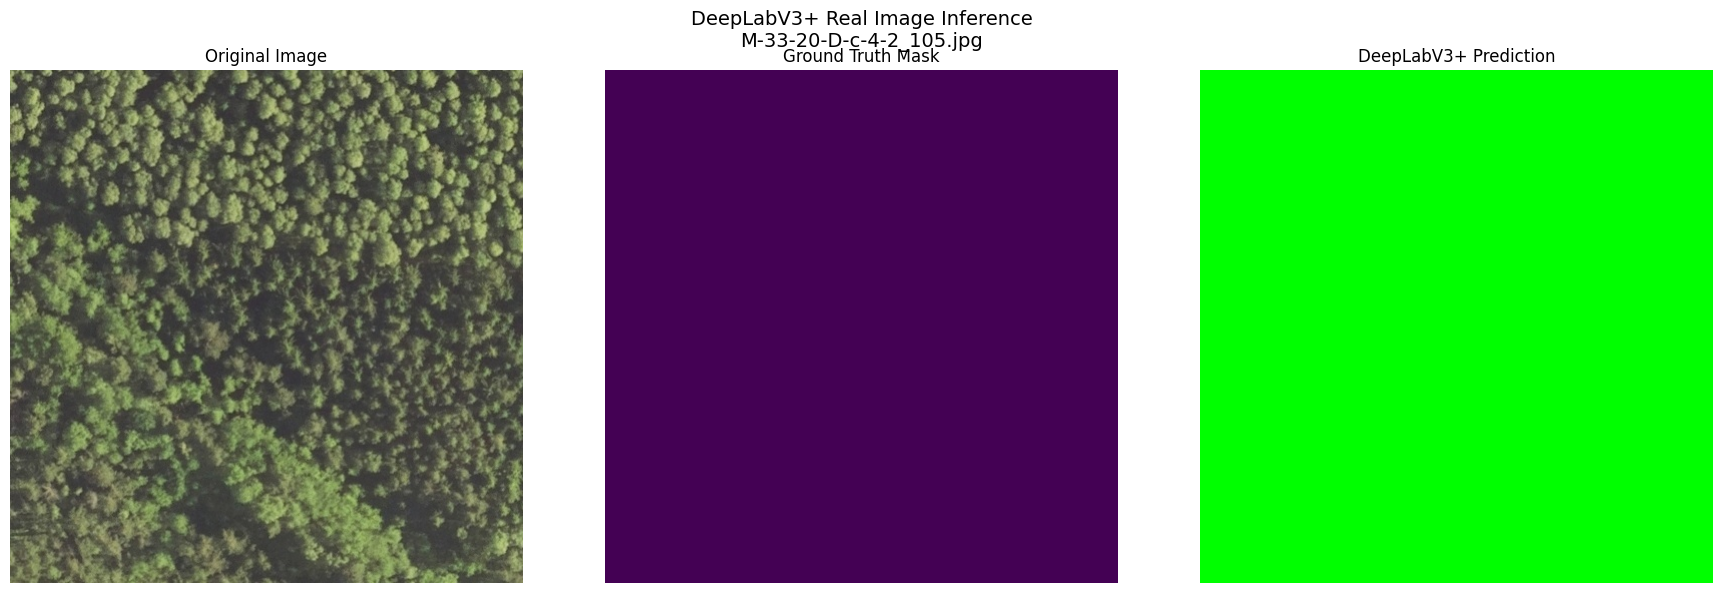

Image: M-33-20-D-c-4-2_105.jpg
Original size: (512, 512)
Ground truth size: (512, 512)
Prediction shape: (512, 512)
Predicted classes: [2]
Comparison saved: True


In [31]:

import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# ==========================================
# 1. Define test paths
# ==========================================
test_images_dir = (
    "/kaggle/input/notebooks/shazahanybakr/"
    "dataset/processed_data/test/images"
)

test_masks_dir = (
    "/kaggle/input/notebooks/shazahanybakr/"
    "dataset/processed_data/test/masks"
)

# ==========================================
# 2. Find test images
# ==========================================
image_files = sorted(
    glob.glob(os.path.join(test_images_dir, "*.jpg"))
)

if not image_files:
    raise FileNotFoundError("No JPG test images found.")

# Select one image
image_path = image_files[0]
image_name = os.path.basename(image_path)

mask_name = os.path.splitext(image_name)[0] + ".png"
mask_path = os.path.join(test_masks_dir, mask_name)

if not os.path.exists(mask_path):
    raise FileNotFoundError(
        f"Matching ground-truth mask not found: {mask_path}"
    )

# ==========================================
# 3. Load original image and ground truth
# ==========================================
original_image = Image.open(image_path).convert("RGB")
ground_truth = Image.open(mask_path)

# ==========================================
# 4. Run DeepLabV3+ prediction
# ==========================================
predicted_mask = predictor.predict(image_path)
colored_prediction = predictor.colorize(predicted_mask)

# ==========================================
# 5. Display comparison
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(original_image)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(ground_truth)
axes[1].set_title("Ground Truth Mask")
axes[1].axis("off")

axes[2].imshow(colored_prediction)
axes[2].set_title("DeepLabV3+ Prediction")
axes[2].axis("off")

plt.suptitle(
    f"DeepLabV3+ Real Image Inference\n{image_name}",
    fontsize=14
)

plt.tight_layout()
plt.show()

# ==========================================
# 6. Save visual comparison
# ==========================================
comparison_path = "/kaggle/working/deeplabv3plus_real_inference.png"

fig.savefig(comparison_path, dpi=150, bbox_inches="tight")
plt.close(fig)

print("Image:", image_name)
print("Original size:", original_image.size)
print("Ground truth size:", ground_truth.size)
print("Prediction shape:", predicted_mask.shape)
print("Predicted classes:", np.unique(predicted_mask))
print("Comparison saved:", os.path.exists(comparison_path))
